In [1]:
import ast
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt

datasets = [ 'cartesian', 'CEP', 'CNP', 'WEP', 'WNP']
directories = [ '/home/gap2/Downloads/PPRL-Dev-main/results/clustering/D8/',
                '/home/gap2/Downloads/PPRL-Dev-main/results/metablocking/D8/clustering/CardinalityEdgePruning/',
                '/home/gap2/Downloads/PPRL-Dev-main/results/metablocking/D8/clustering/CardinalityNodePruning/',
                '/home/gap2/Downloads/PPRL-Dev-main/results/metablocking/D8/clustering/WeightedEdgePruning/',
                '/home/gap2/Downloads/PPRL-Dev-main/results/metablocking/D8/clustering/WeightedNodePruning/'
              ]

In [2]:
def show_diagram(clustering_method, measure, label):
    dfs = []
    for i in range(len(datasets)):
        for sim in ["cosine", "dice", "jaccard"]:
            df = pd.read_csv(directories[i] + str(clustering_method)+f"_{sim}.csv", on_bad_lines="skip")
            df["similarity"] = sim
            df["dataset"] = datasets[i]
            dfs.append(df)

    result = pd.concat(dfs, ignore_index=True)
    result['config_dict'] = result['config'].apply(ast.literal_eval)
    config_cols = pd.json_normalize(result['config_dict'])
    result = result.join(config_cols)
    result = result.drop(columns=['config', 'config_dict'])
    
    max_f1 = result.loc[result.groupby(['num_hashes','dataset', 'similarity'])['F1 %'].idxmax()]
    
    g = sns.relplot(
        data=max_f1,
        x="num_hashes",
        y=measure,
        hue="dataset",
        style="dataset",
        markers=True,
        dashes=False,      # solid lines but different markers
        col="similarity",
        kind="line",
        linewidth=2.5,
        markersize=8
    )

    for ax in g.axes.flat:
        ax.tick_params(axis='both', labelsize=20)

    g.set_axis_labels("Number of Hashes", label, fontsize=20)
    g.set(xlim=(0, None), ylim=(0, 100))
    g.set_titles("{col_name}", size=20)

    plt.tight_layout()
    plt.show()

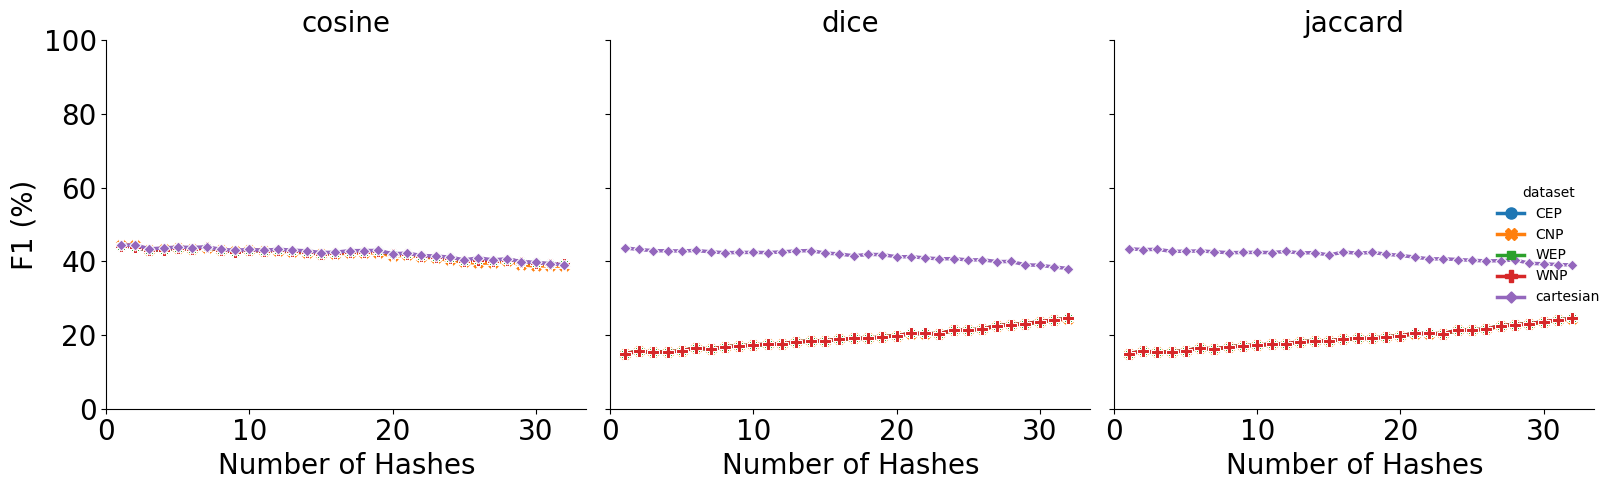

In [3]:
show_diagram("KiralyMSMApproximateClustering", "F1 %", "F1 (%)")

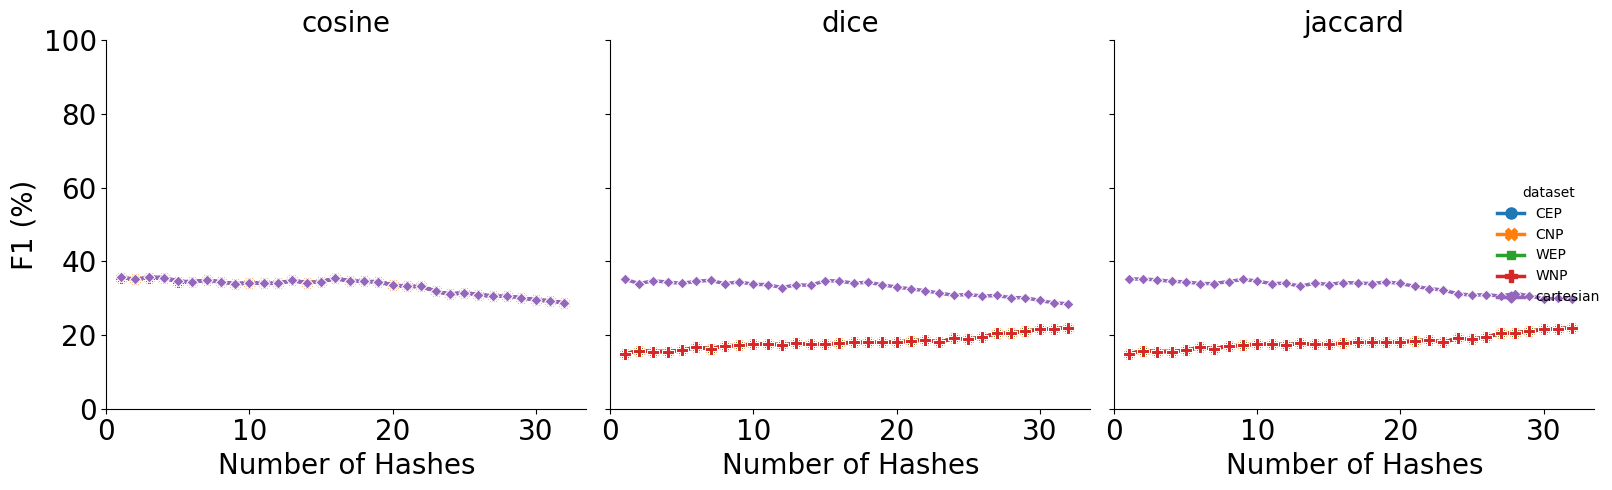

In [4]:
show_diagram("ConnectedComponentsClustering", "F1 %", "F1 (%)")

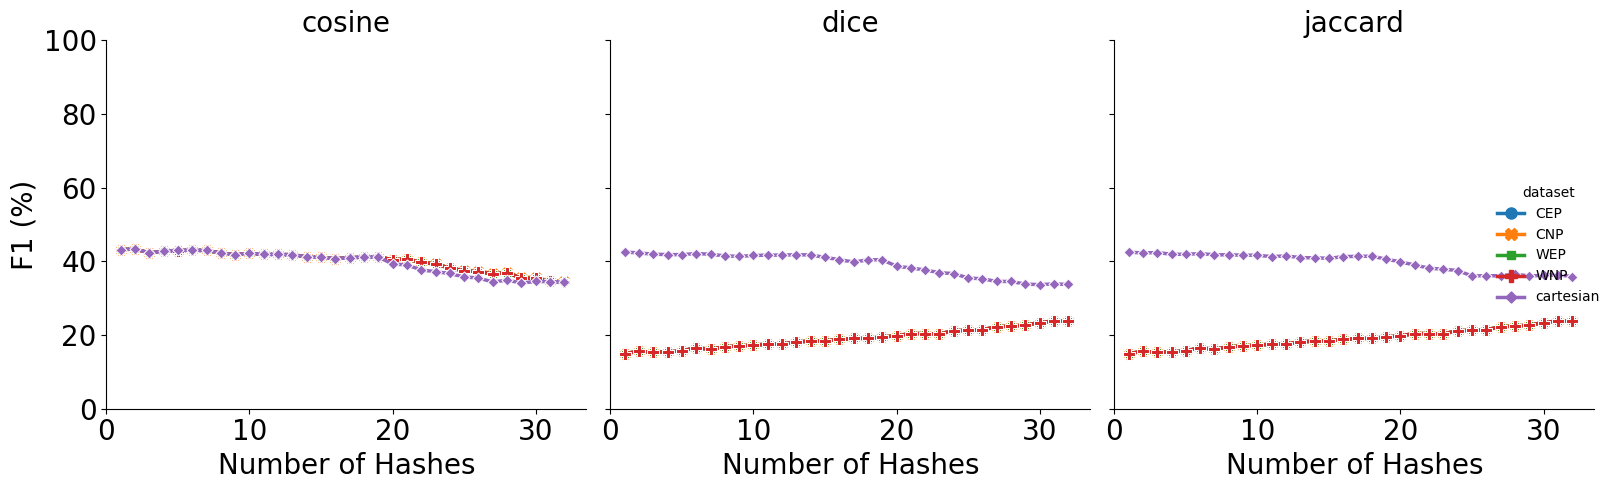

In [5]:
show_diagram("UniqueMappingClustering", "F1 %", "F1 (%)")

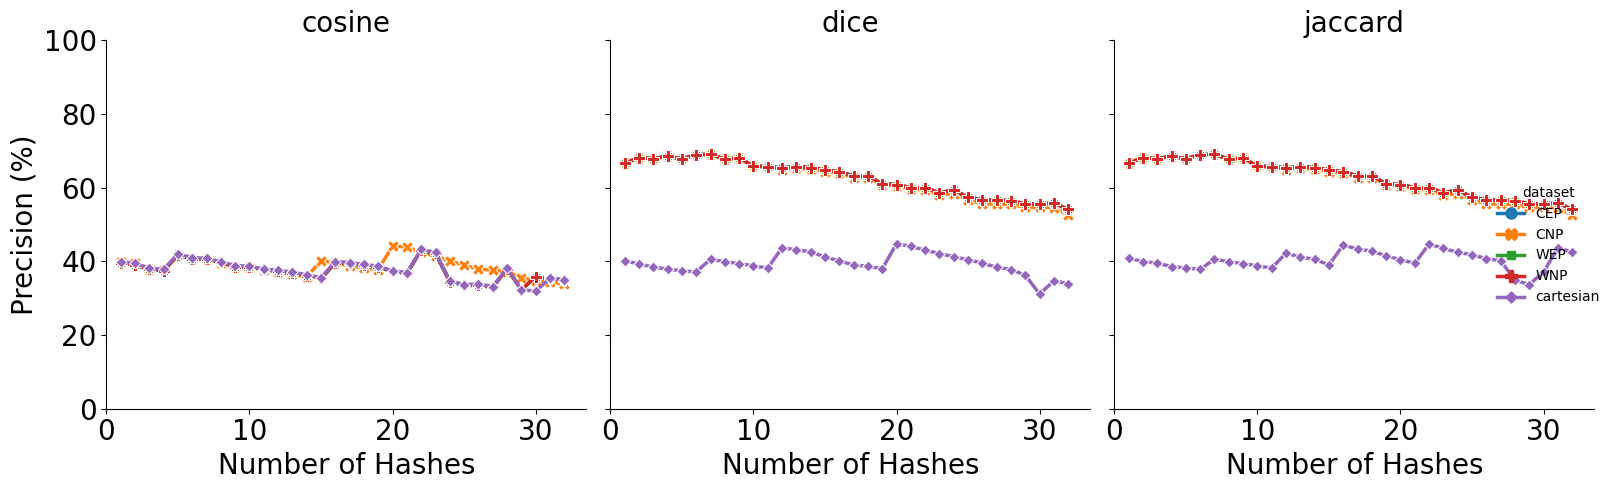

In [6]:
show_diagram("KiralyMSMApproximateClustering", "Precision %", "Precision (%)")

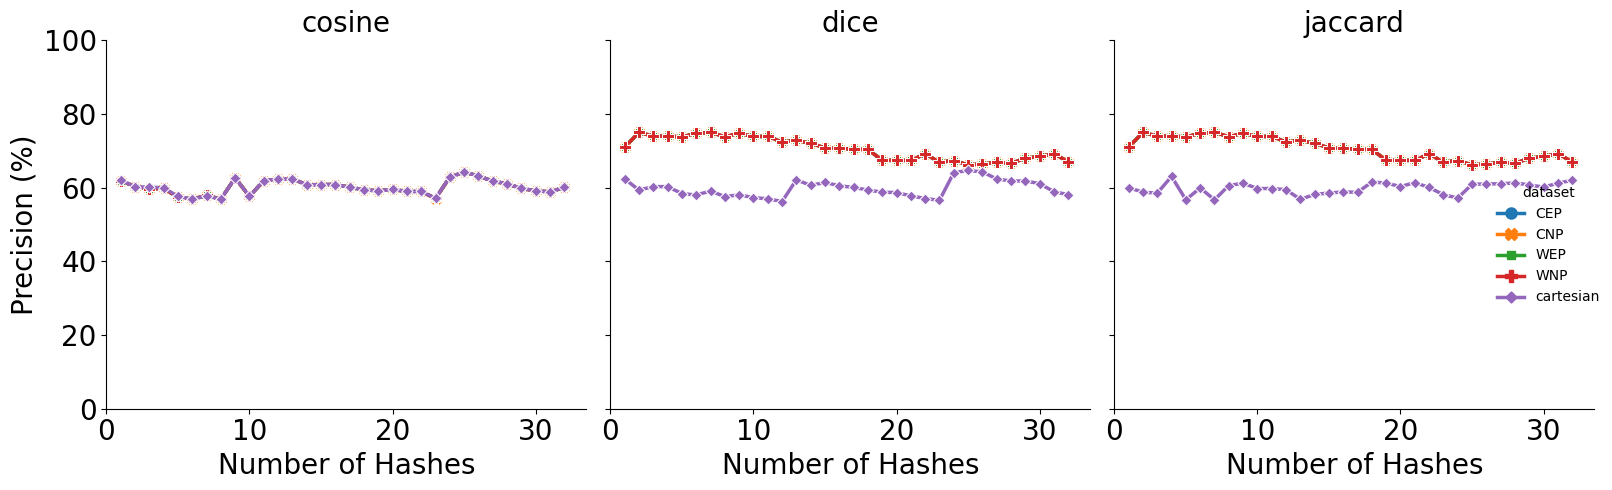

In [7]:
show_diagram("ConnectedComponentsClustering", "Precision %", "Precision (%)")

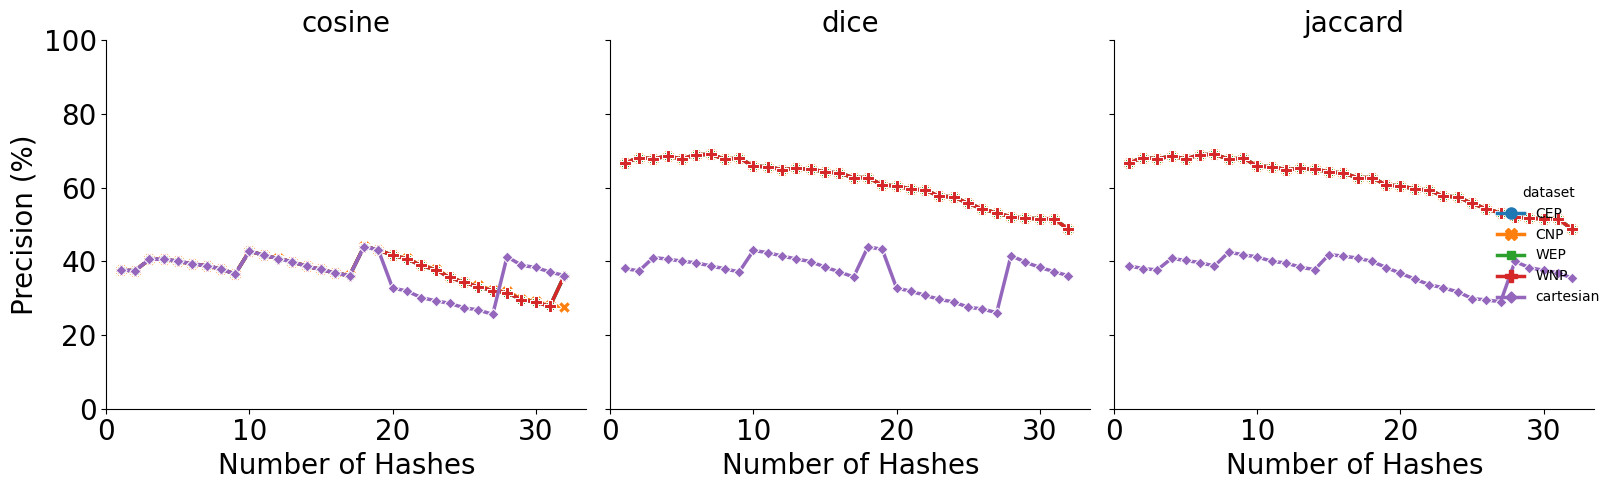

In [8]:
show_diagram("UniqueMappingClustering", "Precision %", "Precision (%)")

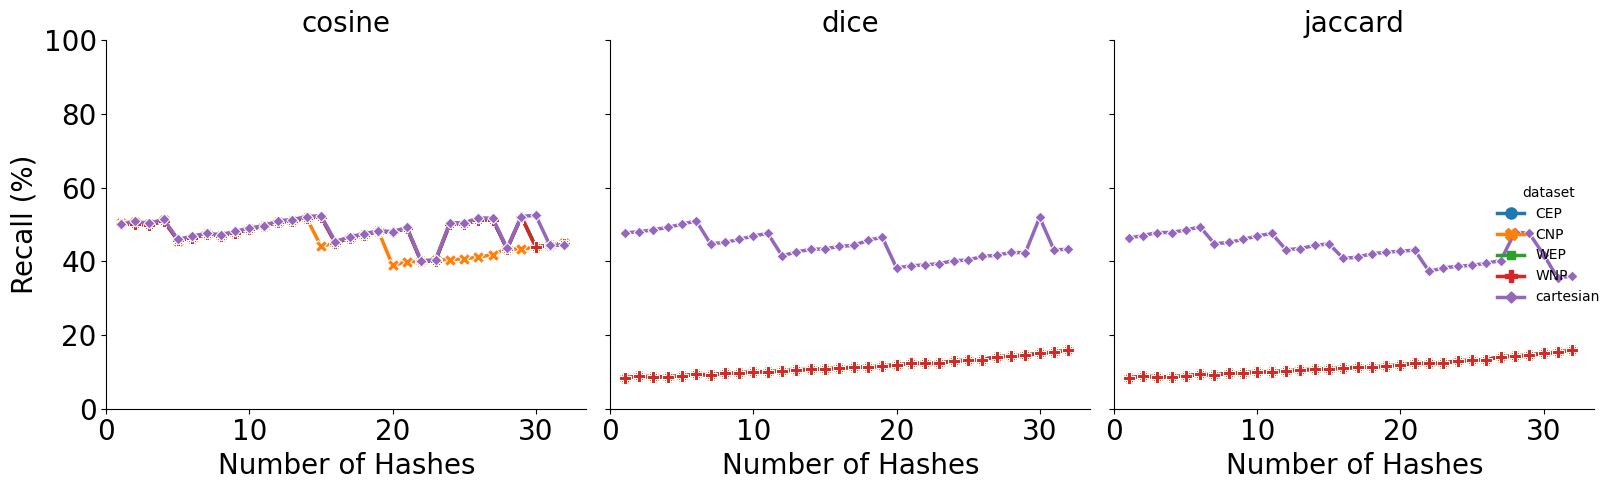

In [9]:
show_diagram("KiralyMSMApproximateClustering", "Recall %", "Recall (%)")

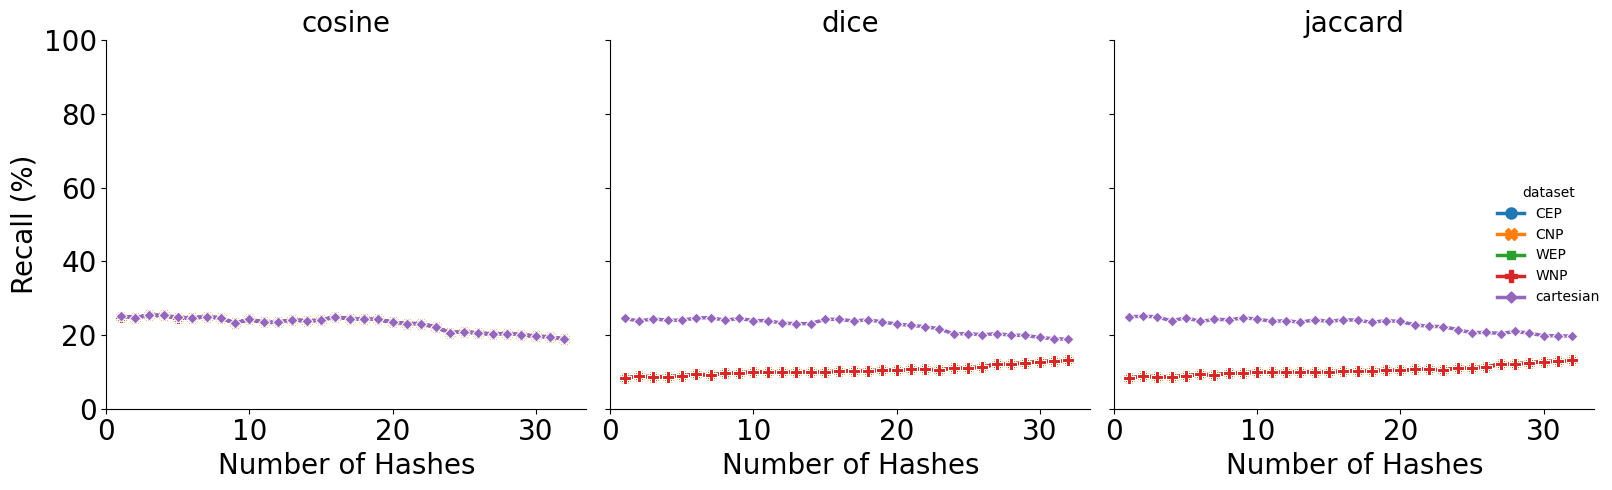

In [10]:
show_diagram("ConnectedComponentsClustering", "Recall %", "Recall (%)")

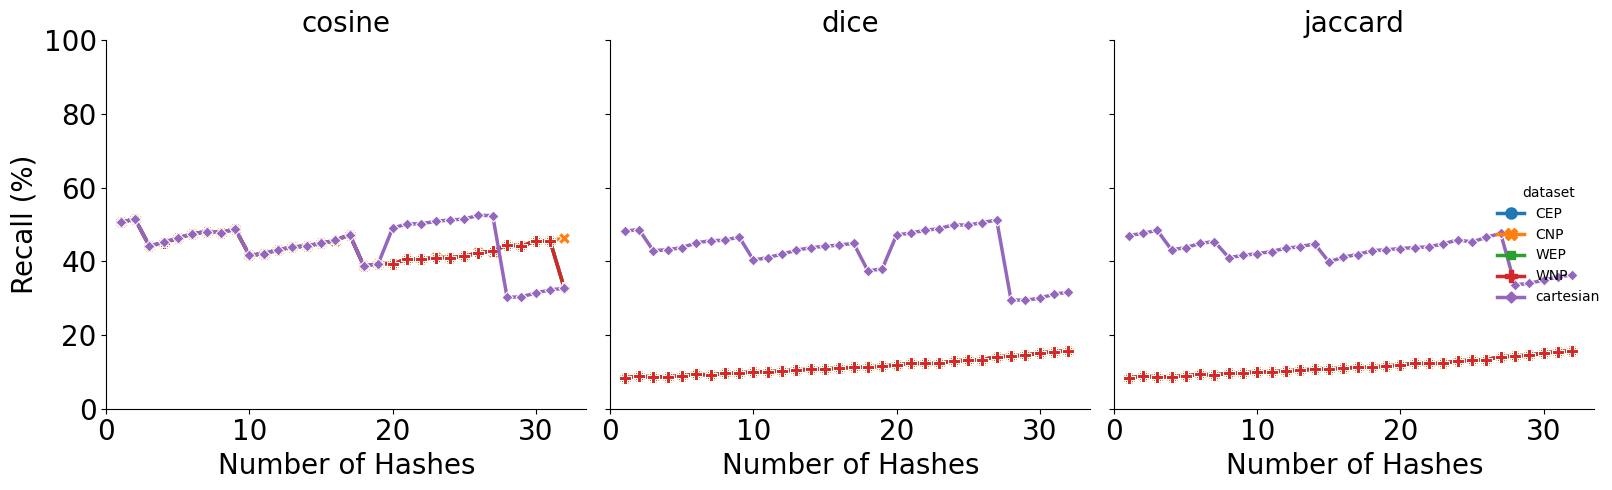

In [11]:
show_diagram("UniqueMappingClustering", "Recall %", "Recall (%)")